# Same predictive representation, three distinct uncertainty targets

This is the first next step from the experiment review: a controlled mathematical study, not a new image benchmark. We ask whether a full second-order predictive law determines target ambiguity and its response to additional information. We construct witnesses separately for known-source membership, reference-anchored label probability, and specified candidate-source membership. They are not additive components of uncertainty.

Every calculation enumerates a finite model exactly; there is no training or Monte Carlo error. Numerical LP and Probly calculations independently check parts of the derivation. Read [the complete propositions and definitions](THREE_TARGET_CHARACTERIZATION.md) alongside this notebook.

**Fundamentals and sources.** Bayes' rule updates hypothesis weights; extrema define support intervals; total variance defines expected squared-error reduction. The factorization criterion is elementary: a target functional is recoverable from a representation exactly when it is constant on every fiber of that representation. The prior counterexample supplies the same-predictive-law idea; `real/source_acquisition.py` supplies the finite-cell ratio solver. Hüllermeier & Waegeman (2021), https://doi.org/10.1007/s10994-021-05946-3, supplies conceptual background; Charnes & Cooper (1962), https://doi.org/10.1002/nav.3800090303, supplies the linear-fractional transformation; https://github.com/pwhofman/probly supplies the independent predictive-MI implementation. These are reused sources, not a new literature review. We do not claim novelty of the general sufficiency criterion or implement DAPPr here.

## 1. Freeze the construction and save provenance

There are three sources, two known and one specified candidate, and three observed cells. Each source has the same cell law `(0.5, 0.3, 0.2)`, so unlabeled cells cannot identify source weights. Independent binary latent indices H and U have a uniform prior. H selects deployment label probability 0.4 or 0.6; U selects hidden source structure. Oracle-U states condition this same prior on U. They are different information states, not different fitted models. Oracle knowledge is not one finite observation.

The three targets at cell zero are k=w0/(w0+w1), l=(theta0+theta1)/2, and n=w2. These simplified expressions require the identical source cell laws and source-specific labels constant across cells. The reference anchor is fixed at equal weights on the known sources. All denominators are positive. The proof document specifies each family's weights and label rates.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, shutil, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from real.three_target_characterization import *
ROOT=Path.cwd()
assert (ROOT/'THREE_TARGET_CHARACTERIZATION.md').exists()
OUT=ROOT/'workbook'/('three_target_characterization_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True)
STATES=['unresolved','oracle_U0','oracle_U1']
FINITE=['unlabeled_input','source_identity','deployment_label','reference_label']
ORACLE=['input_law','source_weights','deployment_label_law','reference_label_laws']
protocol=dict(families=FAMILIES,states=STATES,targets=TARGETS,cell_law=CELL_LAW.tolist(),finite_channels=FINITE,oracle_channels=ORACLE,
              reference_anchor=[.5,.5],prior='independent uniform H,U',interval='support hull, not a confidence or credible interval',
              computation='exact finite enumeration; rational deployment-law cancellation; numerical independent LP checks',seed=None)
(OUT/'protocol.json').write_text(json.dumps(protocol,indent=2))
for src in ['THREE_TARGET_CHARACTERIZATION.md','real/three_target_characterization.py','tests/test_three_target_characterization.py','scripts/build_three_target_characterization.py','real/source_acquisition.py']:
    shutil.copy2(ROOT/src,OUT/Path(src).name)
(OUT/'versions.json').write_text(json.dumps({k:importlib.metadata.version(k) for k in ['numpy','scipy','pandas','torch','probly']},indent=2))
print(OUT)

/home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/three_target_characterization_20261030T144711349004Z


## 2. Compare the entire predictive law, then the target intervals

The representation R is a distribution over joint probability vectors P(cell,label), not just the mean prediction or mutual information. Each state must give equal mass to the same two joint vectors. Consequently every deterministic summary of R agrees, including predictive MI and the label envelope [0.4,0.6]. We also compute a sensitivity interval for MI when the weight on the first atom varies in [0.25,0.75]; this is explicitly not a credible interval.

The decisive comparison is within each family: reveal U without changing R. If a target hull changes, R alone cannot recover that hull. The aligned-reference family is a positive control: its reference label probability equals the deployment label probability, so its target law is recoverable from R.

In [2]:
hypotheses=[]; intervals=[]; summaries=[]; signatures={}
for name in FAMILIES:
    models=family(name)
    for m in models:
        hypotheses.append(dict(family=name,h=m['h'],u=m['u'],weights=json.dumps(m['weights'].tolist()),theta=json.dumps(m['theta'].tolist()),p_exact=m['p_exact'],targets_exact=json.dumps(m['targets_exact'])))
    for state in STATES:
        q=state_weights(models,state);stat=target_statistics(models,q)
        signatures[name+'/'+state]=predictive_signature(models,q)
        summaries.append(dict(family=name,state=state,mean_label=sum(a*m['p'] for a,m in zip(q,models)),mi=predictive_mi(models,q),label_lower=.4,label_upper=.6,
                              mi_sensitivity_lower=float(entropy(.45)-entropy(.4)),mi_sensitivity_upper=float(entropy(.5)-entropy(.4))))
        for j,target in enumerate(TARGETS):
            intervals.append(dict(family=name,state=state,target=target,**{k:float(v[j]) for k,v in stat.items()}))
assert len(set(signatures.values()))==1
pd.DataFrame(hypotheses).to_csv(OUT/'hypotheses.csv',index=False)
intervals=pd.DataFrame(intervals);summaries=pd.DataFrame(summaries)
intervals.to_csv(OUT/'target_intervals.csv',index=False);summaries.to_csv(OUT/'predictive_summaries.csv',index=False)
(OUT/'predictive_laws.json').write_text(json.dumps(signatures,indent=2))
display(summaries)
display(intervals[intervals.family==intervals.target][['family','state','lower','upper','width','variance']])

,family,state,mean_label,mi,label_lower,label_upper,mi_sensitivity_lower,mi_sensitivity_upper
0,known_membership,unresolved,0.5,0.020136,0.4,0.6,0.015127,0.020136
1,known_membership,oracle_U0,0.5,0.020136,0.4,0.6,0.015127,0.020136
2,known_membership,oracle_U1,0.5,0.020136,0.4,0.6,0.015127,0.020136
3,candidate_membership,unresolved,0.5,0.020136,0.4,0.6,0.015127,0.020136
4,candidate_membership,oracle_U0,0.5,0.020136,0.4,0.6,0.015127,0.020136
5,candidate_membership,oracle_U1,0.5,0.020136,0.4,0.6,0.015127,0.020136
6,reference_target,unresolved,0.5,0.020136,0.4,0.6,0.015127,0.020136
7,reference_target,oracle_U0,0.5,0.020136,0.4,0.6,0.015127,0.020136
8,reference_target,oracle_U1,0.5,0.020136,0.4,0.6,0.015127,0.020136
9,aligned_reference_control,unresolved,0.5,0.020136,0.4,0.6,0.015127,0.020136


,family,state,lower,upper,width,variance
0,known_membership,unresolved,0.25,0.75,0.5,0.0625
3,known_membership,oracle_U0,0.25,0.25,0.0,0.0000
6,known_membership,oracle_U1,0.75,0.75,0.0,0.0000
11,candidate_membership,unresolved,0.20,0.60,0.4,0.0400
14,candidate_membership,oracle_U0,0.20,0.20,0.0,0.0000
17,candidate_membership,oracle_U1,0.60,0.60,0.0,0.0000
19,reference_target,unresolved,0.30,0.70,0.4,0.0200
22,reference_target,oracle_U0,0.50,0.70,0.2,0.0100
25,reference_target,oracle_U1,0.30,0.50,0.2,0.0100


## 3. Independently check the predictive MI with Probly

The two exact joint categorical atoms are equally weighted. Probly receives these atoms directly, without dropout, a neural network, or an interval wrapper. This checks the MI calculation only; it cannot validate a claim about trained neural uncertainty estimators.

In [3]:
import torch
from probly.representation.distribution.torch_categorical import TorchProbabilityCategoricalDistribution, TorchCategoricalDistributionSample
from probly.quantification import quantify
atoms=np.array([a for a,mass in next(iter(signatures.values()))])
rep=TorchCategoricalDistributionSample(tensor=TorchProbabilityCategoricalDistribution(torch.tensor(atoms,dtype=torch.float64)),sample_dim=0)
probly_mi=float(quantify(rep).epistemic)
analytic_mi=float(entropy(.5)-entropy(.4))
assert abs(probly_mi-analytic_mi)<1e-12
pd.DataFrame([dict(probly_mi=probly_mi,analytic_mi=analytic_mi,absolute_error=abs(probly_mi-analytic_mi))]).to_csv(OUT/'probly_check.csv',index=False)
print('Identical predictive MI in every state:',analytic_mi,'nats; Probly:',probly_mi)

Identical predictive MI in every state: 0.020135513550688766 nats; Probly: 0.020135513550688655


## 4. Plot static ambiguity and verify membership endpoints independently

Each panel compares an unresolved state with both possible oracle-U states. Reference-target ambiguity changes only in the family where reference and deployment mixtures differ; the aligned panel must remain unchanged. These are separate witnesses, not simultaneous independent changes to three components.

An independent linear-fractional program checks the membership endpoints on a continuous extension of the source-weight sets. Agreement is an endpoint certificate, not a claim that the continuous extension has the same Bayesian prior. Solver status and residuals are saved.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (767 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


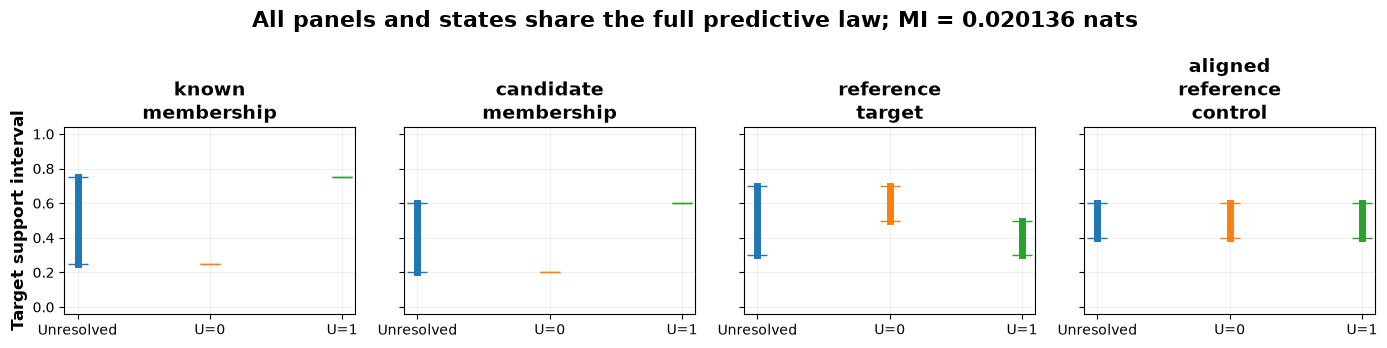

,family,state,lower,upper,width,status,residual
0,known_membership,unresolved,0.25,0.75,0.5,ok,4.440892e-16
1,known_membership,oracle_U0,0.25,0.25,0.0,ok,4.440892e-16
2,known_membership,oracle_U1,0.75,0.75,0.0,ok,4.440892e-16
3,candidate_membership,unresolved,0.20,0.60,0.4,ok,2.220446e-16
4,candidate_membership,oracle_U0,0.20,0.20,0.0,ok,2.220446e-16
5,candidate_membership,oracle_U1,0.60,0.60,0.0,ok,2.220446e-16


In [4]:
fig,axes=plt.subplots(1,4,figsize=(14,3.5),sharey=True)
for ax,name in zip(axes,FAMILIES):
    target='reference_target' if name=='aligned_reference_control' else name
    sub=intervals[(intervals.family==name)&(intervals.target==target)].set_index('state')
    for x,state in enumerate(STATES):
        r=sub.loc[state];ax.plot([x,x],[r.lower,r.upper],lw=5,marker='_',markersize=14)
    ax.set(xticks=range(3),xticklabels=['Unresolved','U=0','U=1'],ylim=(-.04,1.04),title=name.replace('_','\n'))
    ax.grid(alpha=.2)
axes[0].set_ylabel('Target support interval')
fig.suptitle(f'All panels and states share the full predictive law; MI = {analytic_mi:.6f} nats')
fig.tight_layout();fig.savefig(OUT/'target_intervals.png',dpi=180);fig.savefig(OUT/'target_intervals.pdf');plt.show()
certificates=[]
for name in FAMILIES[:2]:
    for state in STATES:
        cert=membership_lp_certificate(name,state)
        r=intervals[(intervals.family==name)&(intervals.state==state)&(intervals.target==name)].iloc[0]
        assert cert['status']=='ok' and np.allclose([cert['lower'],cert['upper']],[r.lower,r.upper],atol=1e-9)
        certificates.append(dict(family=name,state=state,**cert))
pd.DataFrame(certificates).to_csv(OUT/'membership_lp_checks.csv',index=False)
display(pd.DataFrame(certificates))

## 5. Probe reducibility with finite observations and oracle information

One finite observation is drawn from each declared channel: an unlabeled cell; a deployment source identity; a deployment label; or a source-stratified reference label (known source selected with equal probability and its identity recorded). Costs are not compared here. Bayes' rule and exact outcome summation give the expected posterior variance. By total variance, its reduction is the variance of the posterior target mean, and equals the reduction in Bayes squared-error risk.

Every finite likelihood is positive: no hypothesis disappears. Thus finite support widths stay constant even when expected variance falls. This is not a failure to reduce Bayesian uncertainty. Separately, oracle channels reveal an exact input law, source weights, deployment label law, or both known-source label laws. These can eliminate hypotheses and shrink support widths; they are not equally priced finite acquisitions.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (2,718 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


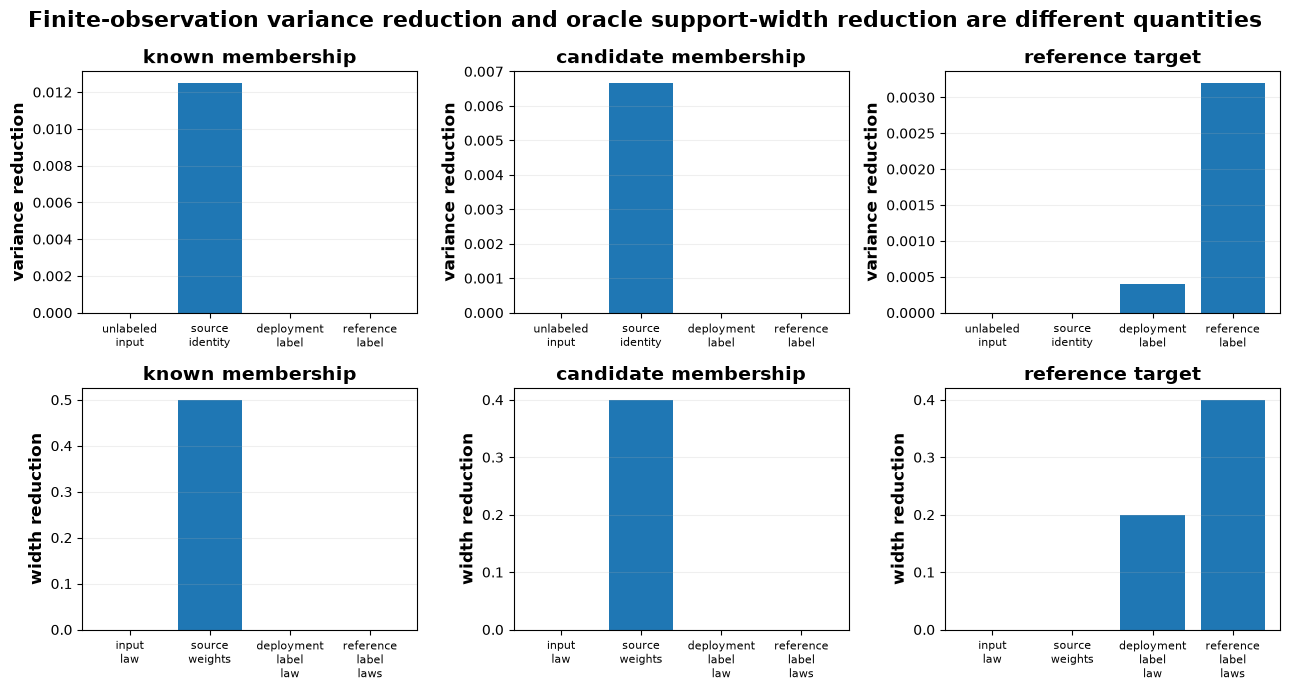

,family,state,channel,target,expected_variance,variance_reduction,expected_width,width_reduction,mi_reduction
0,known_membership,unresolved,unlabeled_input,known_membership,0.062500,0.000000,0.5,0.000000e+00,0.000000e+00
3,known_membership,unresolved,source_identity,known_membership,0.050000,0.012500,0.5,0.000000e+00,-9.020562e-17
6,known_membership,unresolved,deployment_label,known_membership,0.062500,0.000000,0.5,0.000000e+00,8.002135e-04
9,known_membership,unresolved,reference_label,known_membership,0.062500,0.000000,0.5,0.000000e+00,8.002135e-04
38,candidate_membership,unresolved,unlabeled_input,candidate_membership,0.040000,0.000000,0.4,0.000000e+00,0.000000e+00
41,candidate_membership,unresolved,source_identity,candidate_membership,0.033333,0.006667,0.4,-5.551115e-17,-4.510281e-17
44,candidate_membership,unresolved,deployment_label,candidate_membership,0.040000,0.000000,0.4,0.000000e+00,8.002135e-04
47,candidate_membership,unresolved,reference_label,candidate_membership,0.040000,0.000000,0.4,0.000000e+00,8.002135e-04
73,reference_target,unresolved,unlabeled_input,reference_target,0.020000,0.000000,0.4,0.000000e+00,0.000000e+00
76,reference_target,unresolved,source_identity,reference_target,0.020000,0.000000,0.4,0.000000e+00,0.000000e+00


In [5]:
tables={};details={}
for oracle,channels,label in [(False,FINITE,'finite'),(True,ORACLE,'oracle')]:
    rows=[]
    for name in FAMILIES:
        models=family(name)
        for state in STATES:
            q=state_weights(models,state)
            for channel in channels:
                result=expected_update(models,q,channel,oracle=oracle)
                details[f'{label}/{name}/{state}/{channel}']=result['outcomes']
                for j,target in enumerate(TARGETS):
                    rows.append(dict(family=name,state=state,channel=channel,target=target,
                                     **{k:float(result[k][j]) for k in ['expected_variance','variance_reduction','expected_width','width_reduction']},mi_reduction=result['mi_reduction']))
    tables[label]=pd.DataFrame(rows)
    tables[label].to_csv(OUT/f'{label}_acquisition_responses.csv',index=False)
assert np.allclose(tables['finite'].width_reduction,0,atol=1e-12)
assert tables['finite'].variance_reduction.min()>-1e-12
(OUT/'acquisition_outcomes.json').write_text(json.dumps(details,indent=2))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for col,name in enumerate(FAMILIES[:3]):
    for row,label,measure in [(0,'finite','variance_reduction'),(1,'oracle','width_reduction')]:
        sub=tables[label].query('family==@name and target==@name and state=="unresolved"')
        axes[row,col].bar(range(len(sub)),sub[measure]);axes[row,col].set_xticks(range(len(sub)),[x.replace('_','\n') for x in sub.channel],fontsize=8)
        axes[row,col].set_title(name.replace('_',' '));axes[row,col].set_ylabel(measure.replace('_',' '));axes[row,col].grid(axis='y',alpha=.2)
fig.suptitle('Finite-observation variance reduction and oracle support-width reduction are different quantities')
fig.tight_layout();fig.savefig(OUT/'acquisition_responses.png',dpi=180);fig.savefig(OUT/'acquisition_responses.pdf');plt.show()
display(tables['finite'].query('family==target and state=="unresolved"'))

## 6. Check sufficient-information controls and the boundaries of the claim

For the aligned-reference control, the target equals each atom's deployment label probability. Its distribution, interval and deployment-label update are determined by R. This does not imply sufficiency for every possible source-stratified channel.

For membership, replace the confounded cell laws with known affinely independent source laws. The exact marginal then uniquely identifies source weights; the independent LP must give point intervals. This control enriches the representation with source laws and the input marginal. It does not show that label MI alone recovers source membership.

In [6]:
controls=pd.DataFrame(identifiable_source_controls())
assert (controls.status=='ok').all() and np.allclose(controls.width,0,atol=1e-9)
assert np.allclose(controls.lower,controls.truth,atol=1e-9)
controls.to_csv(OUT/'identifiable_source_controls.csv',index=False)
aligned=tables['finite'].query('family=="aligned_reference_control" and target=="reference_target" and channel=="deployment_label"')
assert np.ptp(aligned.variance_reduction)<1e-12
aligned.to_csv(OUT/'aligned_reference_control.csv',index=False)
for name in FAMILIES[:2]:
    r=tables['finite'].query('family==@name and target==@name and channel=="source_identity" and state=="unresolved"').iloc[0]
    assert r.variance_reduction>0 and abs(r.mi_reduction)<1e-12
    models=family(name);before=predictive_signature(models,state_weights(models))
    for outcome in details[f'finite/{name}/unresolved/source_identity']:
        assert predictive_signature(models,np.array(outcome['posterior']))==before
display(controls);display(aligned)

,family,u,target,truth,marginal,affine_rank,lower,upper,width,status,residual
0,known_membership,0,known_membership,0.538462,"[0.28, 0.5, 0.21999999999999997]",2,0.538462,0.538462,0.0,ok,1.387779e-16
1,known_membership,0,candidate_membership,0.071429,"[0.28, 0.5, 0.21999999999999997]",2,0.071429,0.071429,0.0,ok,4.440892e-16
2,known_membership,1,known_membership,0.913043,"[0.48, 0.30000000000000004, 0.21999999999999997]",2,0.913043,0.913043,0.0,ok,2.220446e-16
3,known_membership,1,candidate_membership,0.041667,"[0.48, 0.30000000000000004, 0.21999999999999997]",2,0.041667,0.041667,0.0,ok,2.220446e-16
4,candidate_membership,0,known_membership,0.777778,"[0.38, 0.4, 0.22]",2,0.777778,0.777778,0.0,ok,4.440892e-16
5,candidate_membership,0,candidate_membership,0.052632,"[0.38, 0.4, 0.22]",2,0.052632,0.052632,0.0,ok,4.440892e-16
6,candidate_membership,1,known_membership,0.777778,"[0.24, 0.3, 0.45999999999999996]",2,0.777778,0.777778,0.0,ok,5.551115e-16
7,candidate_membership,1,candidate_membership,0.250000,"[0.24, 0.3, 0.45999999999999996]",2,0.250000,0.250000,0.0,ok,2.664535e-15


,family,state,channel,target,expected_variance,variance_reduction,expected_width,width_reduction,mi_reduction
115,aligned_reference_control,unresolved,deployment_label,reference_target,0.0096,0.0004,0.2,0.0,0.0008
127,aligned_reference_control,oracle_U0,deployment_label,reference_target,0.0096,0.0004,0.2,0.0,0.0008
139,aligned_reference_control,oracle_U1,deployment_label,reference_target,0.0096,0.0004,0.2,0.0,0.0008


## 7. Save the result and state what remains unproved

The evidence establishes a controlled representational insufficiency result. Predictive MI need not be numerically wrong: it measures disagreement about the declared prediction, which can omit uncertainty about another target. Upper/lower bounds on the same projected predictive law cannot recover information lost in that projection. Target-specific bounds use additional structural information, whose assumptions must be stated.

The reference-target witness requires a mismatch between the predictive and reference targets; the aligned positive control forbids a universal failure claim. Membership witnesses require confounding of source input laws. These conditions are part of the result. This study does not establish prevalence in natural images, calibration under estimated source laws, or failure of a trained DAPPr model. It fills the controlled formal step of the paper, not the remaining visual empirical bridge.

In [7]:
lines=['# Controlled three-target characterization: executed results','',
       f'All 12 states have the same second-order law over P(cell,label), with predictive MI {analytic_mi:.12f} nats. Probly agrees to numerical precision.','',
       '| Target / family | Unresolved hull | Oracle U=0 hull | Oracle U=1 hull |',
       '|---|---|---|---|']
for name in FAMILIES:
    target='reference_target' if name=='aligned_reference_control' else name
    sub=intervals[(intervals.family==name)&(intervals.target==target)].set_index('state')
    lines.append('| '+name+' | '+' | '.join(f"[{sub.loc[s,'lower']:.2f}, {sub.loc[s,'upper']:.2f}]" for s in STATES)+' |')
lines+=['','Source-identity observations reduce expected membership variance while preserving the entire predictive law for every realized outcome:','']
for name in FAMILIES[:2]:
    r=tables['finite'].query('family==@name and target==@name and channel=="source_identity" and state=="unresolved"').iloc[0]
    lines.append(f'- {name}: one-observation variance reduction {r.variance_reduction:.8f}; predictive MI reduction zero.')
lines+=['','All finite-observation support widths remain unchanged because all likelihoods are positive. Oracle information can shrink widths. These are distinct conclusions.',
        '', 'Positive controls pass: aligned reference-target uncertainty is determined by the predictive law; known affinely independent source laws plus the exact marginal identify source membership (8 LP checks). Six independent membership LP certificates agree with analytic endpoints.',
        '', 'The three failure witnesses are separate constructions, not an additive decomposition or a simultaneous independent three-component result. The reference-target failure requires reference/deployment mismatch. No natural-image or trained-estimator failure is established here.',
        '', '## Artifacts','', '[Static intervals](target_intervals.png), [acquisition responses](acquisition_responses.png), [target table](target_intervals.csv), [predictive summaries](predictive_summaries.csv), [finite responses](finite_acquisition_responses.csv), [oracle responses](oracle_acquisition_responses.csv), [LP checks](membership_lp_checks.csv), [sufficient source controls](identifiable_source_controls.csv), [Probly check](probly_check.csv), [proof and sources](THREE_TARGET_CHARACTERIZATION.md), [executed notebook](executed.ipynb).',
        '', 'Remaining paper work: image-conditioned target-matched evidence under estimated source laws; transfer and containment checks; representation and discretization sensitivity; precise comparison with existing sufficiency/identification theory. Acquisition-policy superiority is not required by this characterization thesis.']
(OUT/'RESULTS.md').write_text('\n'.join(lines)+'\n')
print('\n'.join(lines))

# Controlled three-target characterization: executed results

All 12 states have the same second-order law over P(cell,label), with predictive MI 0.020135513551 nats. Probly agrees to numerical precision.

| Target / family | Unresolved hull | Oracle U=0 hull | Oracle U=1 hull |
|---|---|---|---|
| known_membership | [0.25, 0.75] | [0.25, 0.25] | [0.75, 0.75] |
| candidate_membership | [0.20, 0.60] | [0.20, 0.20] | [0.60, 0.60] |
| reference_target | [0.30, 0.70] | [0.50, 0.70] | [0.30, 0.50] |
| aligned_reference_control | [0.40, 0.60] | [0.40, 0.60] | [0.40, 0.60] |

Source-identity observations reduce expected membership variance while preserving the entire predictive law for every realized outcome:

- known_membership: one-observation variance reduction 0.01250000; predictive MI reduction zero.
- candidate_membership: one-observation variance reduction 0.00666667; predictive MI reduction zero.

All finite-observation support widths remain unchanged because all likelihoods are posit